# Experiment 4 — Hypothesis Testing (House Price Dataset)

**Covers:** Welch's t-test, z-test, Chi-square test, ANOVA, Tukey HSD, plots, p-value decisions, summary and CSV export.

**Dataset:** **House Price – California Housing** – `housing.csv` from Kaggle ([camnugent/california-housing-prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices)), 20,640 districts, target `median_house_value`, plus income, house age, rooms, population, location and `ocean_proximity`.

**Data file:** keep `housing.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\housing.csv")`).

**Remember:** ttest_ind → ztest → crosstab + chi2_contingency → f_oneway → pairwise_tukeyhsd.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency, f_oneway
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.multicomp import pairwise_tukeyhsd

df = pd.read_csv("housing.csv")

## Decision rule
If p < 0.05 → reject H0, otherwise fail to reject H0.

- **T / Z-test** H0: NEAR BAY and NEAR OCEAN districts have the same mean house value
- **Chi-square** H0: price category (high/low) is independent of ocean proximity
- **ANOVA** H0: mean house value is the same in every ocean-proximity group

In [2]:
# Price category for the Chi-square test
df["Price"] = np.where(df["median_house_value"] > df["median_house_value"].median(), "High", "Low")


def decide(p):
    return "Reject H0" if p < 0.05 else "Fail to reject H0"

## 1. T-test: `median_house_value` by `ocean_proximity` (NEAR BAY vs NEAR OCEAN)

NEAR BAY: 2290 259212.312 122818.537
NEAR OCEAN: 2658 249433.977 122477.146


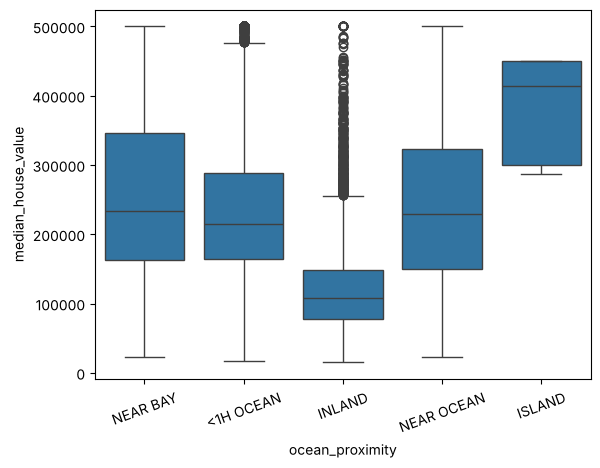

T-test: 2.7960181659007337 0.005194078385610231 Reject H0


In [3]:
g1 = df[df["ocean_proximity"] == "NEAR BAY"]["median_house_value"].dropna()
g2 = df[df["ocean_proximity"] == "NEAR OCEAN"]["median_house_value"].dropna()

print("NEAR BAY:", len(g1), round(g1.mean(), 3), round(g1.std(), 3))
print("NEAR OCEAN:", len(g2), round(g2.mean(), 3), round(g2.std(), 3))

sns.boxplot(data=df, x="ocean_proximity", y="median_house_value")
plt.xticks(rotation=20)
plt.show()

t, p1 = ttest_ind(g1, g2, equal_var=False)
print("T-test:", t, p1, decide(p1))

## 2. Z-test: same two groups (large-sample test of means)

In [4]:
z, p2 = ztest(g1, g2)
print("Z-test:", z, p2, decide(p2))

Z-test: 2.796597171007359 0.005164387863300931 Reject H0


## 3. Chi-square: `ocean_proximity` vs `Price`

Price            High   Low
ocean_proximity            
<1H OCEAN        6071  3065
INLAND            954  5597
ISLAND              5     0
NEAR BAY         1569   721
NEAR OCEAN       1718   940


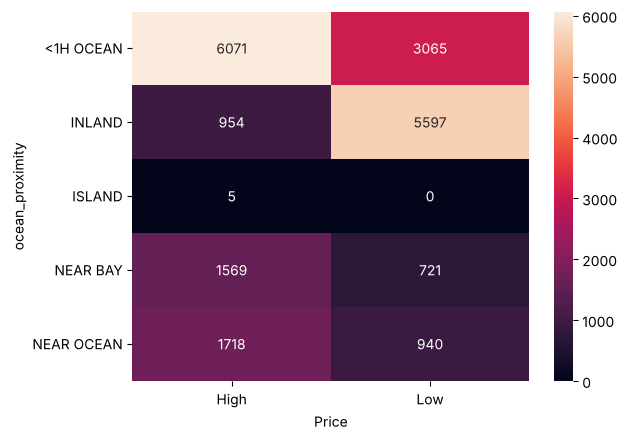

Chi-square: 4826.508893141712 DOF: 4 p: 0.0 Reject H0
Expected frequencies: [[4.5667e+03 4.5693e+03]
 [3.2745e+03 3.2765e+03]
 [2.5000e+00 2.5000e+00]
 [1.1447e+03 1.1453e+03]
 [1.3286e+03 1.3294e+03]]
Expected cells >= 5: 80.0 %


In [5]:
table = pd.crosstab(df["ocean_proximity"], df["Price"])
print(table)

sns.heatmap(table, annot=True, fmt="d")
plt.show()

chi, p3, dof, expected = chi2_contingency(table)
print("Chi-square:", chi, "DOF:", dof, "p:", p3, decide(p3))
print("Expected frequencies:", expected.round(1))
print("Expected cells >= 5:", (expected >= 5).mean() * 100, "%")

## 4. ANOVA: `median_house_value` by `ocean_proximity`

                 count           mean
ocean_proximity                      
<1H OCEAN         9136  240084.285464
INLAND            6551  124805.392001
ISLAND               5  380440.000000
NEAR BAY          2290  259212.311790
NEAR OCEAN        2658  249433.977427


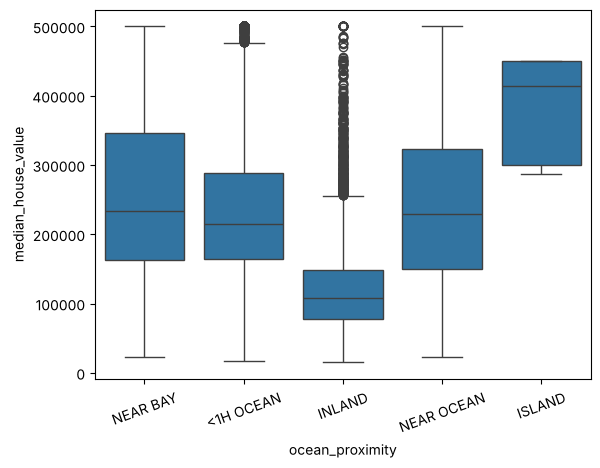

ANOVA: 1612.1407358838221 0.0 Reject H0


In [6]:
groups = [g["median_house_value"].dropna() for _, g in df.groupby("ocean_proximity")]

print(df.groupby("ocean_proximity")["median_house_value"].agg(["count", "mean"]))
sns.boxplot(data=df, x="ocean_proximity", y="median_house_value")
plt.xticks(rotation=20)
plt.show()

f, p4 = f_oneway(*groups)
print("ANOVA:", f, p4, decide(p4))

## 5. Tukey HSD (which pairs differ?)

In [7]:
print(pairwise_tukeyhsd(df["median_house_value"], df["ocean_proximity"]))

           Multiple Comparison of Means - Tukey HSD, FWER=0.05           
  group1    group2     meandiff   p-adj     lower        upper     reject
-------------------------------------------------------------------------
<1H OCEAN     INLAND -115278.8935    0.0 -119727.9273 -110829.8596   True
<1H OCEAN     ISLAND  140355.7145 0.0158   17424.7149  263286.7142   True
<1H OCEAN   NEAR BAY   19128.0263    0.0   12705.8987   25550.1539   True
<1H OCEAN NEAR OCEAN     9349.692 0.0002    3293.4581   15405.9258   True
   INLAND     ISLAND   255634.608    0.0  132690.3424  378578.8736   True
   INLAND   NEAR BAY  134406.9198    0.0  127735.6768  141078.1628   True
   INLAND NEAR OCEAN  124628.5854    0.0  118308.7968  130948.3741   True
   ISLAND   NEAR BAY -121227.6882 0.0557 -244259.1568    1803.7804  False
   ISLAND NEAR OCEAN -131006.0226 0.0302 -254018.9345   -7993.1106   True
 NEAR BAY NEAR OCEAN   -9778.3344  0.006  -17613.4827    -1943.186   True
--------------------------------------

## 6. Summary and save

In [8]:
result = pd.DataFrame({
    "Test": ["T-test", "Z-test", "Chi-square", "ANOVA"],
    "Statistic": [t, z, chi, f],
    "P-value": [p1, p2, p3, p4],
    "Decision": [decide(p) for p in [p1, p2, p3, p4]]
})
print(result)

result.to_csv("hypothesis.csv", index=False)
print("Saved hypothesis.csv")

         Test    Statistic   P-value   Decision
0      T-test     2.796018  0.005194  Reject H0
1      Z-test     2.796597  0.005164  Reject H0
2  Chi-square  4826.508893  0.000000  Reject H0
3       ANOVA  1612.140736  0.000000  Reject H0
Saved hypothesis.csv


## Result / Conclusion
- **T-test / Z-test:** NEAR BAY districts are more expensive than NEAR OCEAN ones (259,212 vs 249,434, t = 2.80, p = 0.005) → reject H0.
- **Chi-square:** price category depends on ocean proximity (χ² = 4,826.5, p ≈ 0). Only 80% of expected counts are ≥ 5, because ISLAND has just 5 districts.
- **ANOVA:** mean house value differs across ocean-proximity groups (F = 1,612, p ≈ 0).
- **Tukey HSD:** every pair differs except ISLAND vs NEAR BAY (p = 0.056).